In [1]:
import os
import urllib.request

CSV_YOLU = "data/mall_customers.csv"
URL = ("https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/"
       "Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/"
       "Section%2025%20-%20Hierarchical%20Clustering/Mall_Customers.csv")

if not os.path.exists(CSV_YOLU):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, CSV_YOLU)
    print("Veri seti indirildi.")
else:
    print("Veri seti mevcut:", CSV_YOLU)

Veri seti mevcut: data/mall_customers.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial import Voronoi, voronoi_plot_2d
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline

df = pd.read_csv(CSV_YOLU)
df = df.rename(columns={"Genre": "Cinsiyet", "Age": "Yas",
                        "Annual Income (k$)": "Gelir", "Spending Score (1-100)": "Harcama"})
print("Veri seti başarıyla yüklendi.")
df.head(10)

Veri seti başarıyla yüklendi.


,CustomerID,Cinsiyet,Yas,Gelir,Harcama
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [3]:
df.tail()

,CustomerID,Cinsiyet,Yas,Gelir,Harcama
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


In [4]:
print(f"Gözlem sayısı  : {df.shape[0]}")
print(f"Değişken sayısı: {df.shape[1]}")
print()
df.info()

Gözlem sayısı  : 200
Değişken sayısı: 5

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   CustomerID  200 non-null    int64
 1   Cinsiyet    200 non-null    str  
 2   Yas         200 non-null    int64
 3   Gelir       200 non-null    int64
 4   Harcama     200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
SAYISAL = ["Yas", "Gelir", "Harcama"]
pd.DataFrame({
    "Eksik Sayısı": df.isna().sum(),
    "Benzersiz Değer": df.nunique(),
    "Veri Tipi": df.dtypes.astype(str),
})

,Eksik Sayısı,Benzersiz Değer,Veri Tipi
CustomerID,0,200,int64
Cinsiyet,0,2,str
Yas,0,51,int64
Gelir,0,64,int64
Harcama,0,84,int64


In [6]:
print("Tekrarlanan satır sayısı      :", df.duplicated().sum())
print("Tekrarlanan CustomerID sayısı :", df["CustomerID"].duplicated().sum())

Tekrarlanan satır sayısı      : 0
Tekrarlanan CustomerID sayısı : 0


,Frekans,Oran (%)
Cinsiyet,,
Female,112,56.000
Male,88,44.000


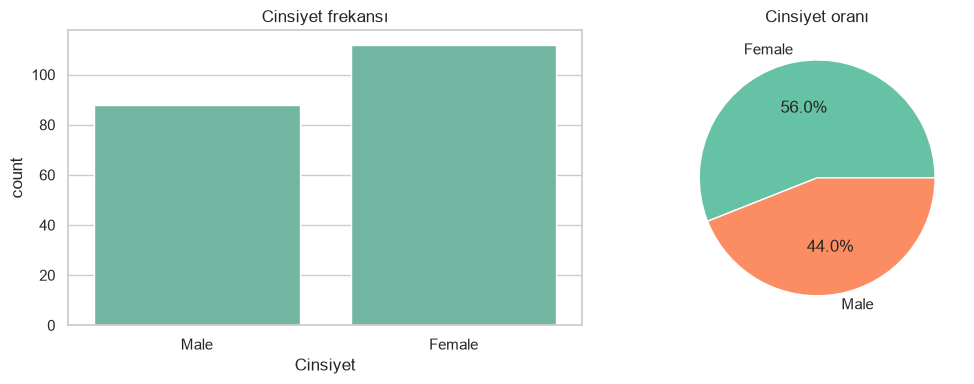

In [7]:
tablo = pd.DataFrame({"Frekans": df["Cinsiyet"].value_counts(),
                      "Oran (%)": df["Cinsiyet"].value_counts(normalize=True) * 100})
display(tablo)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="Cinsiyet", ax=axes[0])
axes[0].set_title("Cinsiyet frekansı")
axes[1].pie(tablo["Frekans"], labels=tablo.index, autopct="%1.1f%%", colors=sns.color_palette("Set2"))
axes[1].set_title("Cinsiyet oranı")
plt.tight_layout()
plt.show()

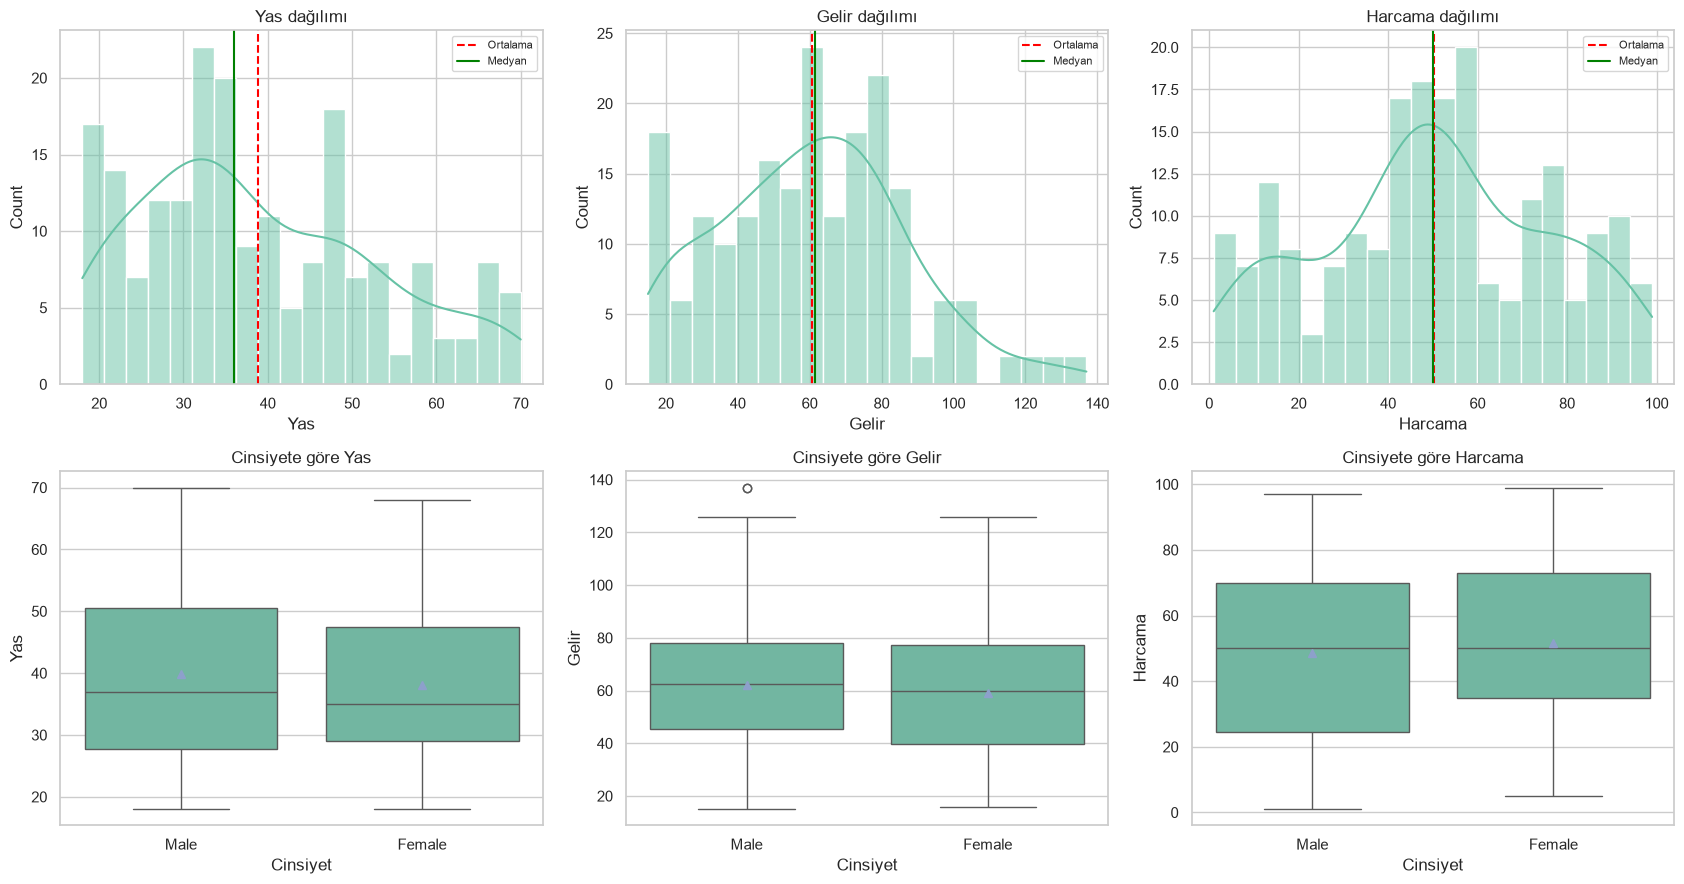

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for i, kol in enumerate(SAYISAL):
    sns.histplot(df[kol], kde=True, bins=20, ax=axes[0, i])
    axes[0, i].axvline(df[kol].mean(), color="red", linestyle="--", label="Ortalama")
    axes[0, i].axvline(df[kol].median(), color="green", label="Medyan")
    axes[0, i].set_title(f"{kol} dağılımı")
    axes[0, i].legend(fontsize=8)
    sns.boxplot(data=df, x="Cinsiyet", y=kol, ax=axes[1, i], showmeans=True)
    axes[1, i].set_title(f"Cinsiyete göre {kol}")
plt.tight_layout()
plt.show()

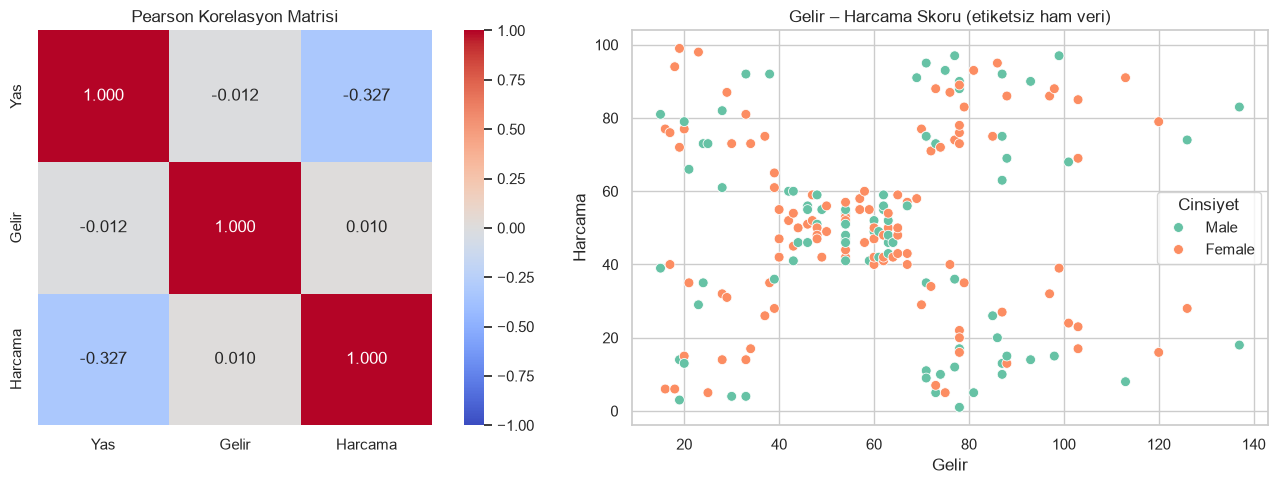

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df[SAYISAL].corr(), annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title("Pearson Korelasyon Matrisi")
sns.scatterplot(data=df, x="Gelir", y="Harcama", hue="Cinsiyet", s=50, ax=axes[1])
axes[1].set_title("Gelir – Harcama Skoru (etiketsiz ham veri)")
plt.tight_layout()
plt.show()

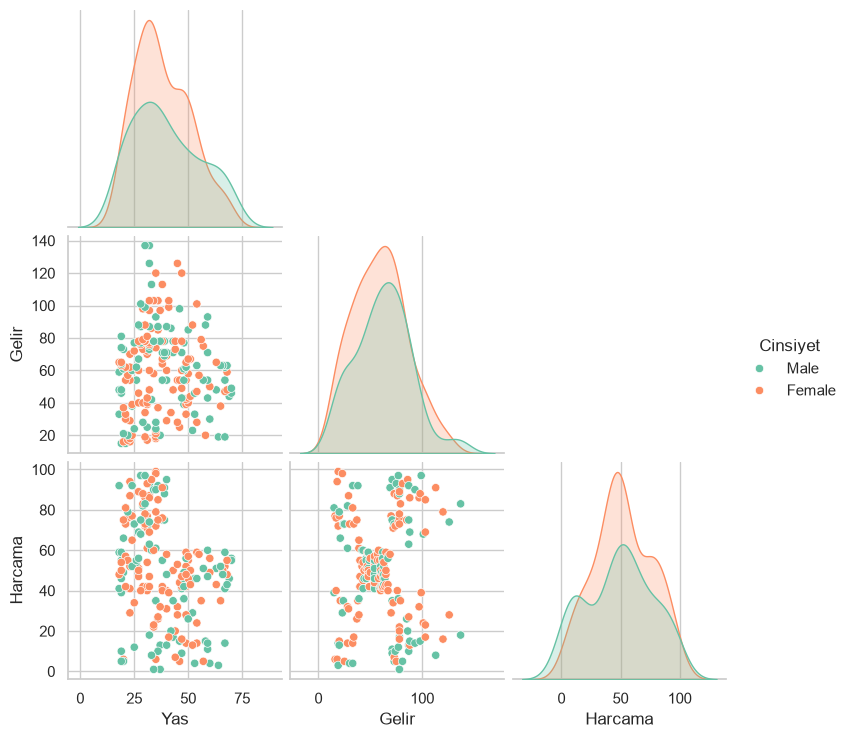

In [10]:
sns.pairplot(df, vars=SAYISAL, hue="Cinsiyet", diag_kind="kde", corner=True)
plt.show()

In [11]:
df[SAYISAL].describe().T

,count,mean,std,min,25%,50%,75%,max
Yas,200.000,38.850,13.969,18.000,28.750,36.000,49.000,70.000
Gelir,200.000,60.560,26.265,15.000,41.500,61.500,78.000,137.000
Harcama,200.000,50.200,25.824,1.000,34.750,50.000,73.000,99.000


In [12]:
def aciklayici_tablo(d):
    satirlar = {}
    for kol in d.columns:
        s = d[kol]
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        satirlar[kol] = {
            "n": s.count(),
            "Ortalama": s.mean(),
            "Medyan": s.median(),
            "Mod": s.mode().iloc[0],
            "Std. Sapma": s.std(),
            "Varyans": s.var(),
            "Std. Hata": stats.sem(s),
            "Değişim Kats. (%)": s.std() / s.mean() * 100,
            "Minimum": s.min(),
            "Q1": q1,
            "Q3": q3,
            "Maksimum": s.max(),
            "Açıklık": s.max() - s.min(),
            "IQR": iqr,
            "Çarpıklık": s.skew(),
            "Basıklık": s.kurt(),
            "Aykırı (1.5·IQR)": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
            "Shapiro-Wilk p": stats.shapiro(s).pvalue,
        }
    return pd.DataFrame(satirlar)

aciklayici_tablo(df[SAYISAL])

,Yas,Gelir,Harcama
n,200.000,200.000,200.000
Ortalama,38.850,60.560,50.200
Medyan,36.000,61.500,50.000
Mod,32.000,54.000,42.000
Std. Sapma,13.969,26.265,25.824
Varyans,195.133,689.836,666.854
Std. Hata,0.988,1.857,1.826
Değişim Kats. (%),35.956,43.370,51.441
Minimum,18.000,15.000,1.000
Q1,28.750,41.500,34.750


In [13]:
df.groupby("Cinsiyet")[SAYISAL].agg(["mean", "median", "std", "min", "max"]).T

Cinsiyet        Female    Male
Yas     mean    38.098  39.807
        median  35.000  37.000
        std     12.644  15.515
        min     18.000  18.000
        max     68.000  70.000
Gelir   mean    59.250  62.227
        median  60.000  62.500
        std     26.012  26.638
        min     16.000  15.000
        max    126.000 137.000
Harcama mean    51.527  48.511
        median  50.000  50.000
        std     24.115  27.897
        min      5.000   1.000
        max     99.000  97.000

In [14]:
K = 5

DEGISKENLER = ["Gelir", "Harcama"]
X = df[DEGISKENLER].values

olcekleyici = StandardScaler()
X_olcekli = olcekleyici.fit_transform(X)

kmeans = KMeans(n_clusters=K, init="k-means++", n_init=10, max_iter=300, random_state=42)
etiketler = kmeans.fit_predict(X_olcekli)

print(f"Girilen küme sayısı (k)  : {K}")
print(f"Yakınsama iterasyonu     : {kmeans.n_iter_}")
print(f"WCSS (inertia)           : {kmeans.inertia_:.3f}")
print(f"Silhouette skoru         : {silhouette_score(X_olcekli, etiketler):.4f}")

Girilen küme sayısı (k)  : 5
Yakınsama iterasyonu     : 4
WCSS (inertia)           : 65.568
Silhouette skoru         : 0.5547


In [15]:
merkezler = pd.DataFrame(olcekleyici.inverse_transform(kmeans.cluster_centers_), columns=DEGISKENLER)

sira = merkezler.sort_values(["Gelir", "Harcama"]).index
yeni_no = {eski: yeni + 1 for yeni, eski in enumerate(sira)}
df["Kume"] = pd.Series(etiketler).map(yeni_no).values
merkezler = merkezler.loc[sira].reset_index(drop=True)
merkezler.index = merkezler.index + 1
merkezler.index.name = "Kume"

def seviye(deger, alt, ust):
    return "Düşük" if deger < alt else ("Yüksek" if deger > ust else "Orta")

def segment_adi(m):
    gelir = seviye(m["Gelir"], df["Gelir"].quantile(0.33), df["Gelir"].quantile(0.67))
    harcama = seviye(m["Harcama"], 40, 60)
    return f"{gelir} gelir – {harcama} harcama"

merkezler["Segment"] = merkezler.apply(segment_adi, axis=1)
df["Segment"] = df["Kume"].map(merkezler["Segment"])
merkezler

,Gelir,Harcama,Segment
Kume,,,
1,25.727,79.364,Düşük gelir – Yüksek harcama
2,26.304,20.913,Düşük gelir – Düşük harcama
3,55.296,49.519,Orta gelir – Orta harcama
4,86.538,82.128,Yüksek gelir – Yüksek harcama
5,88.200,17.114,Yüksek gelir – Düşük harcama


In [16]:
df[["CustomerID", "Cinsiyet", "Yas", "Gelir", "Harcama", "Kume", "Segment"]].sample(10, random_state=1)

,CustomerID,Cinsiyet,Yas,Gelir,Harcama,Kume,Segment
58,59,Female,27,46,51,3,Orta gelir – Orta harcama
40,41,Female,65,38,35,2,Düşük gelir – Düşük harcama
34,35,Female,49,33,14,2,Düşük gelir – Düşük harcama
102,103,Male,67,62,59,3,Orta gelir – Orta harcama
184,185,Female,41,99,39,5,Yüksek gelir – Düşük harcama
198,199,Male,32,137,18,5,Yüksek gelir – Düşük harcama
95,96,Male,24,60,52,3,Orta gelir – Orta harcama
4,5,Female,31,17,40,2,Düşük gelir – Düşük harcama
29,30,Female,23,29,87,1,Düşük gelir – Yüksek harcama
168,169,Female,36,87,27,5,Yüksek gelir – Düşük harcama


In [17]:
CIKTI = "data/mall_customers_etiketli.csv"
df.to_csv(CIKTI, index=False)
print("Etiketlenmiş veri kaydedildi:", CIKTI)

Etiketlenmiş veri kaydedildi: data/mall_customers_etiketli.csv


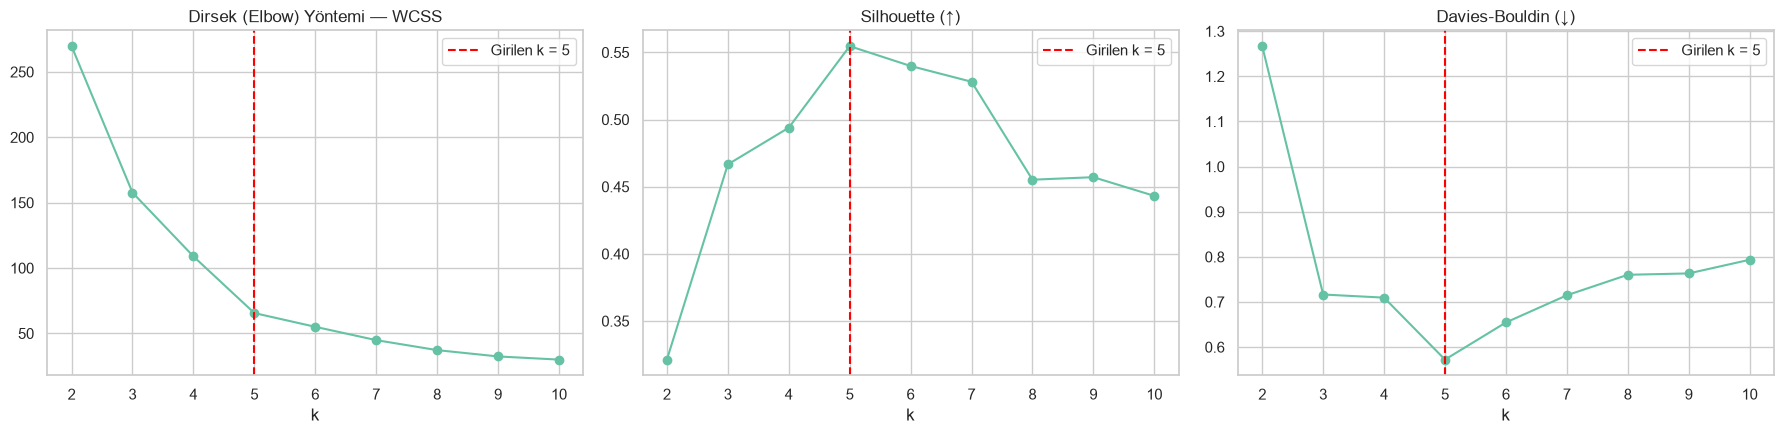

,WCSS (inertia),Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
k,,,,
2,269.691,0.321,1.267,95.669
3,157.704,0.467,0.716,151.335
4,108.921,0.494,0.710,174.595
5,65.568,0.555,0.572,248.649
6,55.057,0.540,0.655,243.088
7,44.865,0.528,0.715,254.621
8,37.228,0.455,0.760,267.279
9,32.392,0.457,0.763,270.948
10,29.982,0.443,0.793,260.540


In [18]:
olcutler = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_olcekli)
    olcutler.append({
        "k": k,
        "WCSS (inertia)": km.inertia_,
        "Silhouette (↑)": silhouette_score(X_olcekli, km.labels_),
        "Davies-Bouldin (↓)": davies_bouldin_score(X_olcekli, km.labels_),
        "Calinski-Harabasz (↑)": calinski_harabasz_score(X_olcekli, km.labels_),
    })
olcutler = pd.DataFrame(olcutler).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, kol in zip(axes, ["WCSS (inertia)", "Silhouette (↑)", "Davies-Bouldin (↓)"]):
    ax.plot(olcutler.index, olcutler[kol], marker="o")
    ax.axvline(K, color="red", linestyle="--", label=f"Girilen k = {K}")
    ax.set_title(kol)
    ax.set_xlabel("k")
    ax.legend()
axes[0].set_title("Dirsek (Elbow) Yöntemi — WCSS")
plt.tight_layout()
plt.show()

olcutler.style.highlight_max(subset=["Silhouette (↑)", "Calinski-Harabasz (↑)"], color="lightgreen") \
              .highlight_min(subset=["Davies-Bouldin (↓)"], color="lightgreen").format("{:.3f}")

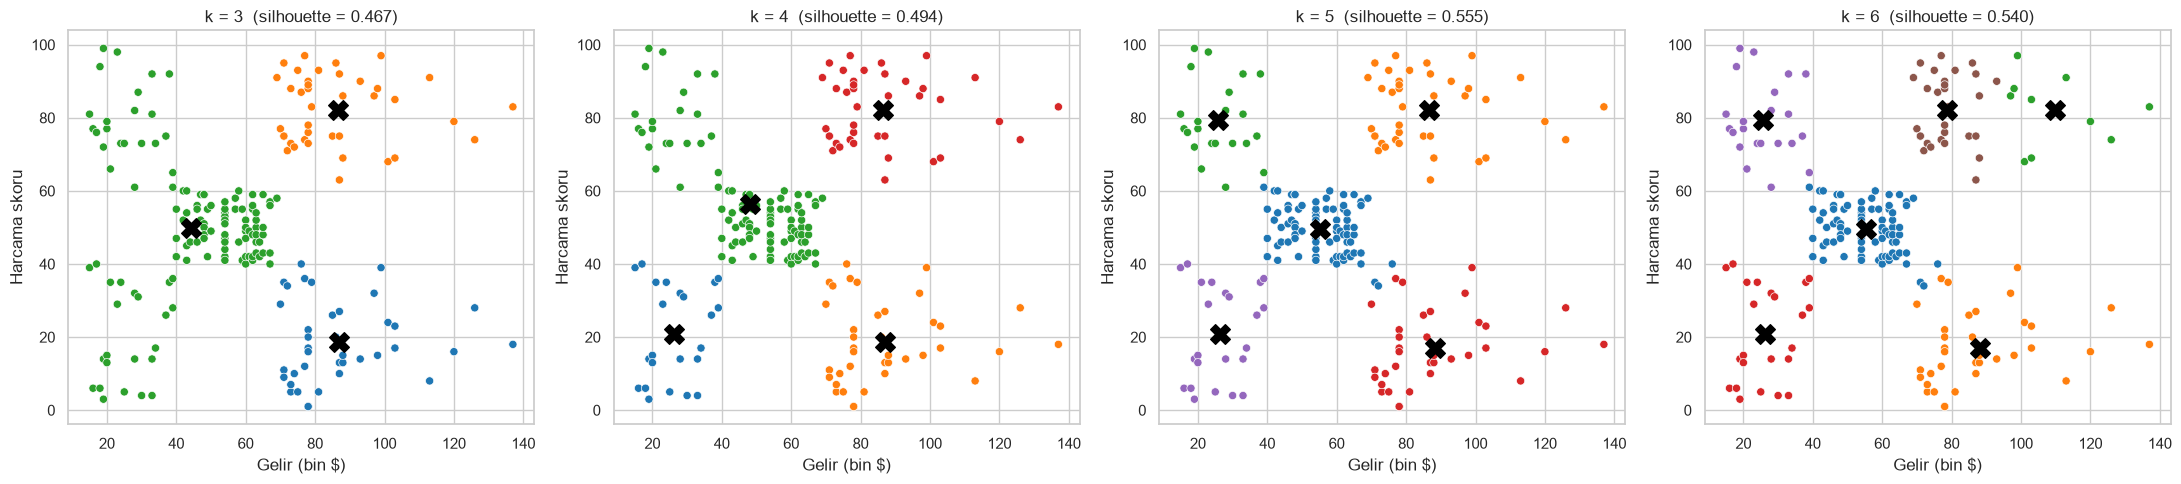

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, k in zip(axes, [3, 4, 5, 6]):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_olcekli)
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=km.labels_, palette="tab10", ax=ax, legend=False, s=35)
    m = olcekleyici.inverse_transform(km.cluster_centers_)
    ax.scatter(m[:, 0], m[:, 1], c="black", marker="X", s=200)
    ax.set_title(f"k = {k}  (silhouette = {silhouette_score(X_olcekli, km.labels_):.3f})")
    ax.set_xlabel("Gelir (bin $)")
    ax.set_ylabel("Harcama skoru")
plt.tight_layout()
plt.show()

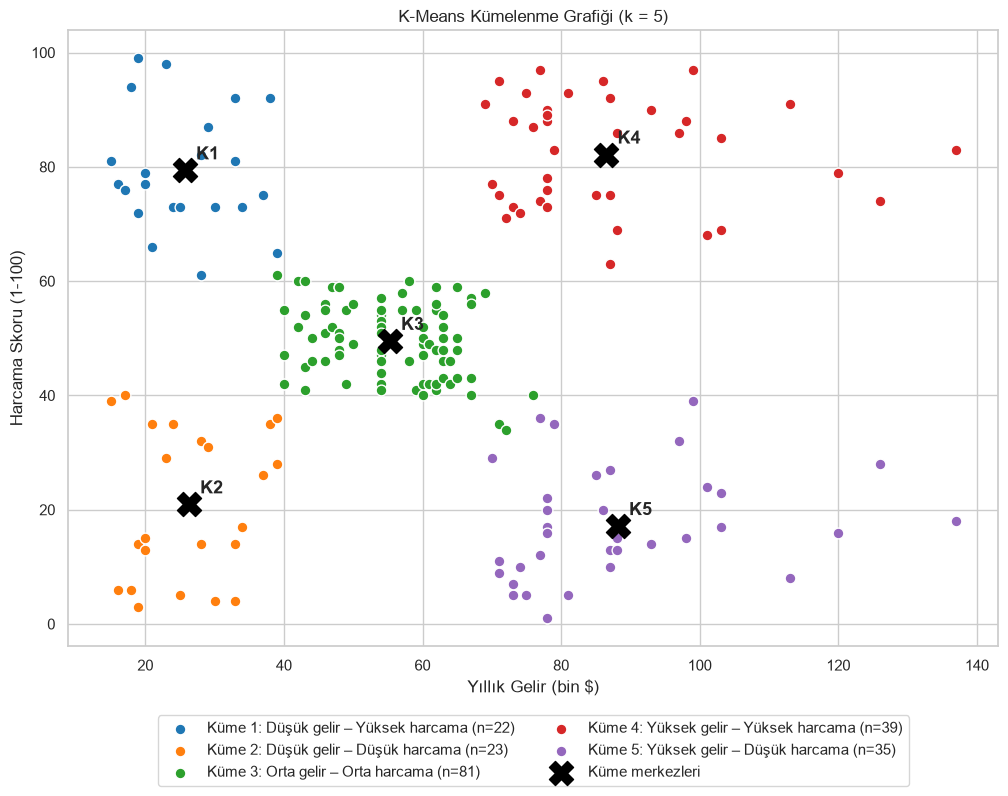

In [20]:
RENKLER = sns.color_palette("tab10", K)

fig, ax = plt.subplots(figsize=(12, 8))
for k in range(1, K + 1):
    alt = df[df["Kume"] == k]
    ax.scatter(alt["Gelir"], alt["Harcama"], s=60, color=RENKLER[k - 1], edgecolor="white",
               label=f"Küme {k}: {merkezler.loc[k, 'Segment']} (n={len(alt)})")
ax.scatter(merkezler["Gelir"], merkezler["Harcama"], c="black", marker="X", s=300, label="Küme merkezleri")
for k, m in merkezler.iterrows():
    ax.annotate(f"K{k}", (m["Gelir"], m["Harcama"]), xytext=(8, 8), textcoords="offset points",
                fontsize=13, fontweight="bold")
ax.set_xlabel("Yıllık Gelir (bin $)")
ax.set_ylabel("Harcama Skoru (1-100)")
ax.set_title(f"K-Means Kümelenme Grafiği (k = {K})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.show()

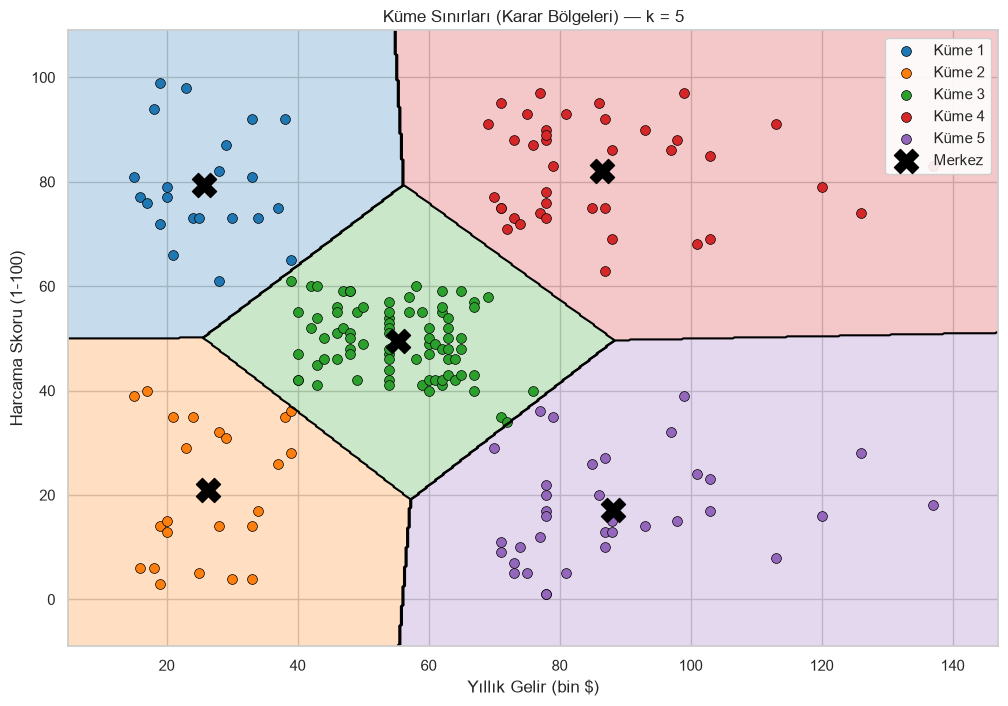

In [21]:
x_min, x_max = X[:, 0].min() - 10, X[:, 0].max() + 10
y_min, y_max = X[:, 1].min() - 10, X[:, 1].max() + 10
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 600), np.linspace(y_min, y_max, 600))
izgara_tahmin = kmeans.predict(olcekleyici.transform(np.c_[xx.ravel(), yy.ravel()]))
izgara_kume = pd.Series(izgara_tahmin).map(yeni_no).values.reshape(xx.shape)

from matplotlib.colors import ListedColormap
cmap = ListedColormap(RENKLER)

fig, ax = plt.subplots(figsize=(12, 8))
ax.contourf(xx, yy, izgara_kume, levels=np.arange(0.5, K + 1.5), cmap=cmap, alpha=0.25)
ax.contour(xx, yy, izgara_kume, levels=np.arange(1.5, K + 0.5), colors="black", linewidths=1.5)
for k in range(1, K + 1):
    alt = df[df["Kume"] == k]
    ax.scatter(alt["Gelir"], alt["Harcama"], s=50, color=RENKLER[k - 1], edgecolor="black", linewidth=0.5,
               label=f"Küme {k}")
ax.scatter(merkezler["Gelir"], merkezler["Harcama"], c="black", marker="X", s=300, label="Merkez")
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xlabel("Yıllık Gelir (bin $)")
ax.set_ylabel("Harcama Skoru (1-100)")
ax.set_title(f"Küme Sınırları (Karar Bölgeleri) — k = {K}")
ax.legend(loc="upper right", framealpha=0.9)
plt.show()

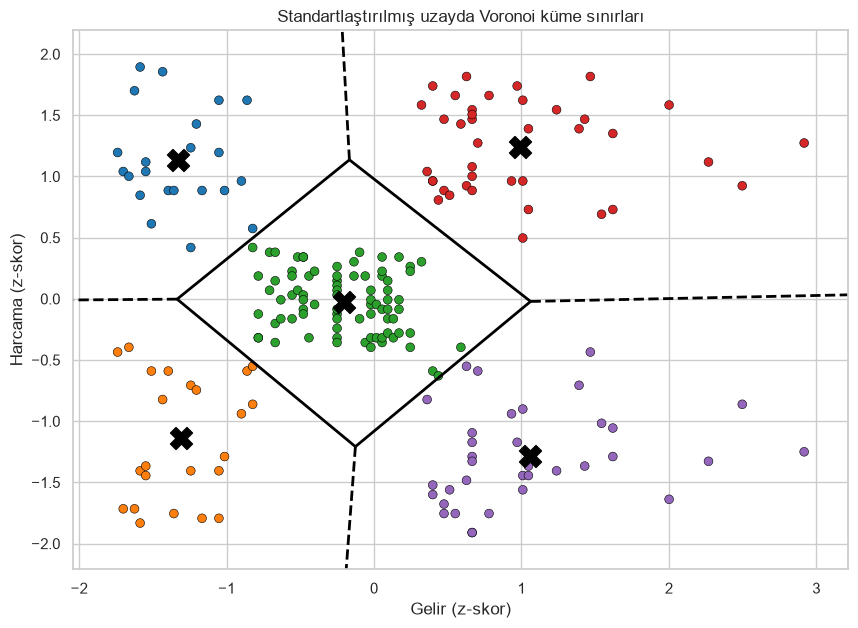

In [22]:
fig, ax = plt.subplots(figsize=(10, 7))
voronoi_plot_2d(Voronoi(kmeans.cluster_centers_), ax=ax, show_vertices=False, line_colors="black",
                line_width=2, show_points=False)
ax.scatter(X_olcekli[:, 0], X_olcekli[:, 1], c=[RENKLER[k - 1] for k in df["Kume"]], s=40, edgecolor="black",
           linewidth=0.4)
ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="black", marker="X", s=250)
ax.set_xlim(X_olcekli[:, 0].min() - 0.3, X_olcekli[:, 0].max() + 0.3)
ax.set_ylim(X_olcekli[:, 1].min() - 0.3, X_olcekli[:, 1].max() + 0.3)
ax.set_xlabel("Gelir (z-skor)")
ax.set_ylabel("Harcama (z-skor)")
ax.set_title("Standartlaştırılmış uzayda Voronoi küme sınırları")
plt.show()

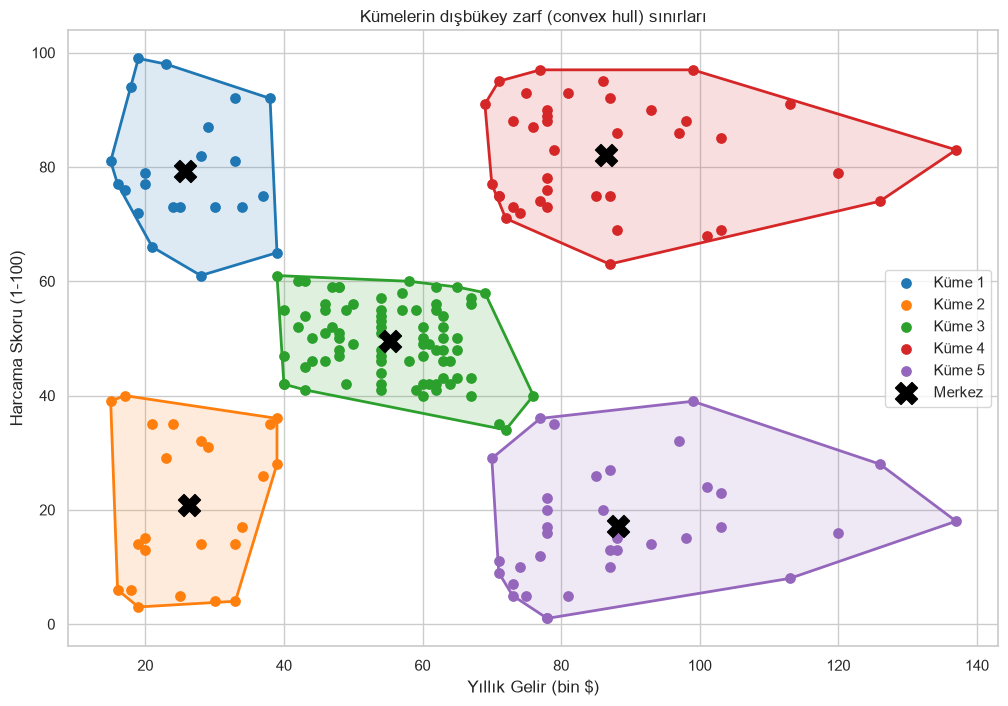

In [23]:
from scipy.spatial import ConvexHull

fig, ax = plt.subplots(figsize=(12, 8))
for k in range(1, K + 1):
    noktalar = df.loc[df["Kume"] == k, DEGISKENLER].values
    ax.scatter(noktalar[:, 0], noktalar[:, 1], s=45, color=RENKLER[k - 1], label=f"Küme {k}")
    if len(noktalar) >= 3:
        zarf = ConvexHull(noktalar)
        kapali = np.append(zarf.vertices, zarf.vertices[0])
        ax.fill(noktalar[kapali, 0], noktalar[kapali, 1], color=RENKLER[k - 1], alpha=0.15)
        ax.plot(noktalar[kapali, 0], noktalar[kapali, 1], color=RENKLER[k - 1], linewidth=2)
ax.scatter(merkezler["Gelir"], merkezler["Harcama"], c="black", marker="X", s=250, label="Merkez")
ax.set_xlabel("Yıllık Gelir (bin $)")
ax.set_ylabel("Harcama Skoru (1-100)")
ax.set_title("Kümelerin dışbükey zarf (convex hull) sınırları")
ax.legend()
plt.show()

In [24]:
sil_ornek = silhouette_samples(X_olcekli, etiketler)
df["Silhouette"] = sil_ornek

genel = pd.Series({
    "Gözlem sayısı": len(df),
    "Kümeleme değişkenleri": ", ".join(DEGISKENLER),
    "Ölçekleme": "StandardScaler (z-skor)",
    "Algoritma": "K-Means (k-means++, n_init=10)",
    "Küme sayısı (k)": K,
    "İterasyon sayısı": kmeans.n_iter_,
    "WCSS (küme içi KT, ölçekli)": round(kmeans.inertia_, 3),
    "Silhouette skoru (-1…1, ↑)": round(silhouette_score(X_olcekli, etiketler), 4),
    "Davies-Bouldin indeksi (↓)": round(davies_bouldin_score(X_olcekli, etiketler), 4),
    "Calinski-Harabasz indeksi (↑)": round(calinski_harabasz_score(X_olcekli, etiketler), 2),
    "Negatif silhouette'li gözlem": int((sil_ornek < 0).sum()),
}).to_frame("Değer")
genel

,Değer
Gözlem sayısı,200
Kümeleme değişkenleri,"Gelir, Harcama"
Ölçekleme,StandardScaler (z-skor)
Algoritma,"K-Means (k-means++, n_init=10)"
Küme sayısı (k),5
İterasyon sayısı,4
"WCSS (küme içi KT, ölçekli)",65.568
"Silhouette skoru (-1…1, ↑)",0.555
Davies-Bouldin indeksi (↓),0.572
Calinski-Harabasz indeksi (↑),248.650


In [25]:
TSS = ((X - X.mean(axis=0)) ** 2).sum()
WSS = sum(((df.loc[df["Kume"] == k, DEGISKENLER].values - merkezler.loc[k, DEGISKENLER].values.astype(float)) ** 2).sum()
          for k in range(1, K + 1))
BSS = TSS - WSS
print(f"Toplam kareler toplamı (TSS)        : {TSS:,.1f}")
print(f"Küme içi kareler toplamı (WSS)      : {WSS:,.1f}")
print(f"Kümeler arası kareler toplamı (BSS) : {BSS:,.1f}")
print(f"BSS / TSS                           : %{BSS / TSS * 100:.2f}  → toplam değişimin bu kadarı kümelerle açıklanıyor")

Toplam kareler toplamı (TSS)        : 269,981.3
Küme içi kareler toplamı (WSS)      : 44,448.5
Kümeler arası kareler toplamı (BSS) : 225,532.8
BSS / TSS                           : %83.54  → toplam değişimin bu kadarı kümelerle açıklanıyor


In [26]:
rapor = df.groupby("Kume").agg(
    Segment=("Segment", "first"),
    Musteri_Sayisi=("CustomerID", "count"),
    Oran_Yuzde=("CustomerID", lambda s: len(s) / len(df) * 100),
    Gelir_Ort=("Gelir", "mean"),
    Gelir_Min=("Gelir", "min"),
    Gelir_Max=("Gelir", "max"),
    Harcama_Ort=("Harcama", "mean"),
    Harcama_Min=("Harcama", "min"),
    Harcama_Max=("Harcama", "max"),
    Yas_Ort=("Yas", "mean"),
    Kadin_Orani_Yuzde=("Cinsiyet", lambda s: (s == "Female").mean() * 100),
    Silhouette_Ort=("Silhouette", "mean"),
)
rapor["Merkeze_Ort_Uzaklik"] = [
    np.linalg.norm(X_olcekli[df["Kume"] == k] - kmeans.cluster_centers_[sira[k - 1]], axis=1).mean()
    for k in rapor.index
]
rapor

,Segment,Musteri_Sayisi,Oran_Yuzde,Gelir_Ort,Gelir_Min,Gelir_Max,Harcama_Ort,Harcama_Min,Harcama_Max,Yas_Ort,Kadin_Orani_Yuzde,Silhouette_Ort,Merkeze_Ort_Uzaklik
Kume,,,,,,,,,,,,,
1,Düşük gelir – Yüksek harcama,22,11.000,25.727,15,39,79.364,61,99,25.273,59.091,0.598,0.447
2,Düşük gelir – Düşük harcama,23,11.500,26.304,15,39,20.913,3,40,45.217,60.870,0.511,0.549
3,Orta gelir – Orta harcama,81,40.500,55.296,39,76,49.519,34,61,42.716,59.259,0.598,0.387
4,Yüksek gelir – Yüksek harcama,39,19.500,86.538,69,137,82.128,63,97,32.692,53.846,0.511,0.627
5,Yüksek gelir – Düşük harcama,35,17.500,88.200,70,137,17.114,1,39,41.114,45.714,0.505,0.625


In [27]:
print("Küme merkezleri arası uzaklıklar (standartlaştırılmış uzay)")
m_olcekli = kmeans.cluster_centers_[sira]
pd.DataFrame(np.linalg.norm(m_olcekli[:, None] - m_olcekli[None, :], axis=2),
             index=[f"K{k}" for k in range(1, K + 1)], columns=[f"K{k}" for k in range(1, K + 1)])

Küme merkezleri arası uzaklıklar (standartlaştırılmış uzay)


,K1,K2,K3,K4,K5
K1,0.000,2.269,1.617,2.324,3.395
K2,2.269,0.000,1.568,3.307,2.367
K3,1.617,1.568,0.000,1.739,1.778
K4,2.324,3.307,1.739,0.000,2.525
K5,3.395,2.367,1.778,2.525,0.000


In [28]:
df.groupby("Kume")[SAYISAL].describe().T

Kume               1      2      3       4       5
Yas     count 22.000 23.000 81.000  39.000  35.000
        mean  25.273 45.217 42.716  32.692  41.114
        std    5.257 13.229 16.448   3.729  11.342
        min   18.000 19.000 18.000  27.000  19.000
        25%   21.250 35.500 27.000  30.000  34.000
        50%   23.500 46.000 46.000  32.000  42.000
        75%   29.750 53.500 54.000  35.500  47.500
        max   35.000 67.000 70.000  40.000  59.000
Gelir   count 22.000 23.000 81.000  39.000  35.000
        mean  25.727 26.304 55.296  86.538  88.200
        std    7.567  7.894  8.988  16.312  16.399
        min   15.000 15.000 39.000  69.000  70.000
        25%   19.250 19.500 48.000  75.500  77.500
        50%   24.500 25.000 54.000  79.000  85.000
        75%   32.250 33.000 62.000  95.000  97.500
        max   39.000 39.000 76.000 137.000 137.000
Harcama count 22.000 23.000 81.000  39.000  35.000
        mean  79.364 20.913 49.519  82.128  17.114
        std   10.504 13.017  6.531   9.364   9.952
        min   61.000  3.000 34.000  63.000   1.000
        25%   73.000  9.500 44.000  74.500  10.000
        50%   77.000 17.000 50.000  83.000  16.000
        75%   85.750 33.500 55.000  90.000  23.500
        max   99.000 40.000 61.000  97.000  39.000

In [29]:
testler = []
for kol in SAYISAL:
    h, p = stats.kruskal(*[df.loc[df["Kume"] == k, kol] for k in range(1, K + 1)])
    testler.append({"Değişken": kol, "H": h, "p-değeri": p, "Kümeler arası fark": "Anlamlı" if p < 0.05 else "Anlamsız"})
ki_kare = stats.chi2_contingency(pd.crosstab(df["Kume"], df["Cinsiyet"]))
testler.append({"Değişken": "Cinsiyet (χ²)", "H": ki_kare.statistic, "p-değeri": ki_kare.pvalue,
                "Kümeler arası fark": "Anlamlı" if ki_kare.pvalue < 0.05 else "Anlamsız"})
pd.DataFrame(testler).set_index("Değişken")

,H,p-değeri,Kümeler arası fark
Değişken,,,
Yas,41.510,0.000,Anlamlı
Gelir,172.097,0.000,Anlamlı
Harcama,174.777,0.000,Anlamlı
Cinsiyet (χ²),2.232,0.693,Anlamsız


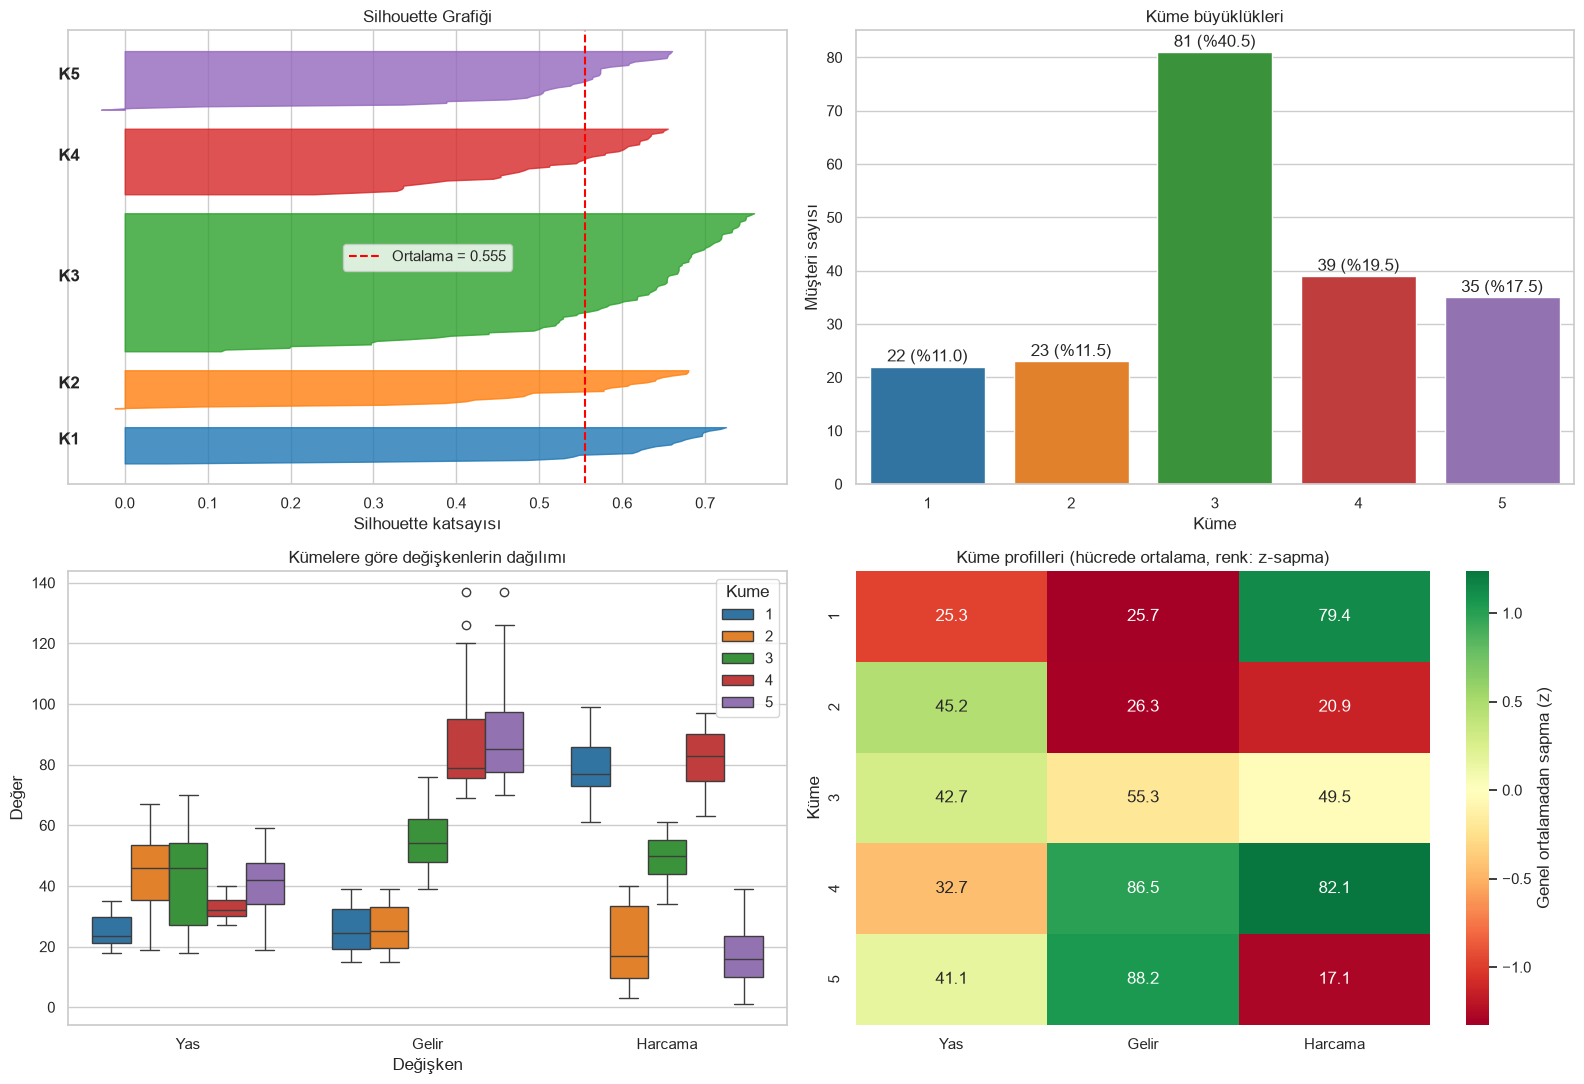

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

ax = axes[0, 0]
y_alt = 10
for k in range(1, K + 1):
    degerler = np.sort(df.loc[df["Kume"] == k, "Silhouette"].values)
    ax.fill_betweenx(np.arange(y_alt, y_alt + len(degerler)), 0, degerler, color=RENKLER[k - 1], alpha=0.8)
    ax.text(-0.08, y_alt + len(degerler) / 2, f"K{k}", fontweight="bold")
    y_alt += len(degerler) + 10
ax.axvline(df["Silhouette"].mean(), color="red", linestyle="--", label=f"Ortalama = {df['Silhouette'].mean():.3f}")
ax.set_title("Silhouette Grafiği")
ax.set_xlabel("Silhouette katsayısı")
ax.set_yticks([])
ax.legend()

ax = axes[0, 1]
sns.barplot(x=rapor.index, y=rapor["Musteri_Sayisi"], hue=rapor.index, palette=RENKLER, legend=False, ax=ax)
for i, (n, o) in enumerate(zip(rapor["Musteri_Sayisi"], rapor["Oran_Yuzde"])):
    ax.text(i, n + 1, f"{n} (%{o:.1f})", ha="center")
ax.set_title("Küme büyüklükleri")
ax.set_xlabel("Küme")
ax.set_ylabel("Müşteri sayısı")

uzun = df.melt(id_vars="Kume", value_vars=SAYISAL, var_name="Değişken", value_name="Değer")
sns.boxplot(data=uzun, x="Değişken", y="Değer", hue="Kume", palette=RENKLER, ax=axes[1, 0])
axes[1, 0].set_title("Kümelere göre değişkenlerin dağılımı")

profil = df.groupby("Kume")[SAYISAL].mean()
profil_z = (profil - df[SAYISAL].mean()) / df[SAYISAL].std()
sns.heatmap(profil_z, annot=profil.round(1), fmt="", cmap="RdYlGn", center=0, ax=axes[1, 1],
            cbar_kws={"label": "Genel ortalamadan sapma (z)"})
axes[1, 1].set_title("Küme profilleri (hücrede ortalama, renk: z-sapma)")
axes[1, 1].set_ylabel("Küme")

plt.tight_layout()
plt.show()

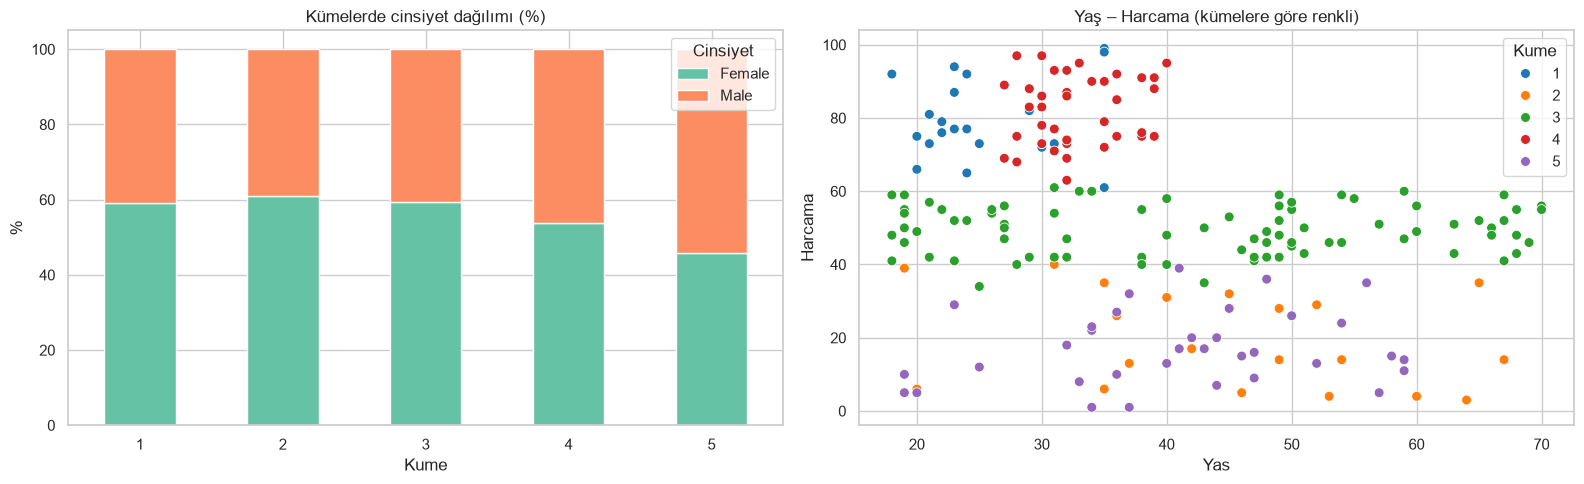

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
pd.crosstab(df["Kume"], df["Cinsiyet"], normalize="index").mul(100).plot.bar(stacked=True, ax=axes[0], rot=0)
axes[0].set_title("Kümelerde cinsiyet dağılımı (%)")
axes[0].set_ylabel("%")
sns.scatterplot(data=df, x="Yas", y="Harcama", hue="Kume", palette=RENKLER, s=50, ax=axes[1])
axes[1].set_title("Yaş – Harcama (kümelere göre renkli)")
plt.tight_layout()
plt.show()

In [32]:
print("=" * 78)
print(f"{'KÜMELENME RAPORU':^78}")
print("=" * 78)
print(f"Yöntem: K-Means | k = {K} | Değişkenler: {', '.join(DEGISKENLER)} | n = {len(df)}")
print(f"Silhouette = {silhouette_score(X_olcekli, etiketler):.3f} | "
      f"Davies-Bouldin = {davies_bouldin_score(X_olcekli, etiketler):.3f} | BSS/TSS = %{BSS / TSS * 100:.1f}")
print("-" * 78)
for k, r in rapor.iterrows():
    print(f"Küme {k} — {r['Segment']}")
    print(f"   Müşteri: {r['Musteri_Sayisi']} (%{r['Oran_Yuzde']:.1f})   "
          f"Gelir ort.: {r['Gelir_Ort']:.1f} bin $ [{r['Gelir_Min']}–{r['Gelir_Max']}]   "
          f"Harcama ort.: {r['Harcama_Ort']:.1f} [{r['Harcama_Min']}–{r['Harcama_Max']}]")
    print(f"   Yaş ort.: {r['Yas_Ort']:.1f}   Kadın oranı: %{r['Kadin_Orani_Yuzde']:.0f}   "
          f"Ort. silhouette: {r['Silhouette_Ort']:.3f}")
print("=" * 78)

                               KÜMELENME RAPORU                               
Yöntem: K-Means | k = 5 | Değişkenler: Gelir, Harcama | n = 200
Silhouette = 0.555 | Davies-Bouldin = 0.572 | BSS/TSS = %83.5
------------------------------------------------------------------------------
Küme 1 — Düşük gelir – Yüksek harcama
   Müşteri: 22 (%11.0)   Gelir ort.: 25.7 bin $ [15–39]   Harcama ort.: 79.4 [61–99]
   Yaş ort.: 25.3   Kadın oranı: %59   Ort. silhouette: 0.598
Küme 2 — Düşük gelir – Düşük harcama
   Müşteri: 23 (%11.5)   Gelir ort.: 26.3 bin $ [15–39]   Harcama ort.: 20.9 [3–40]
   Yaş ort.: 45.2   Kadın oranı: %61   Ort. silhouette: 0.511
Küme 3 — Orta gelir – Orta harcama
   Müşteri: 81 (%40.5)   Gelir ort.: 55.3 bin $ [39–76]   Harcama ort.: 49.5 [34–61]
   Yaş ort.: 42.7   Kadın oranı: %59   Ort. silhouette: 0.598
Küme 4 — Yüksek gelir – Yüksek harcama
   Müşteri: 39 (%19.5)   Gelir ort.: 86.5 bin $ [69–137]   Harcama ort.: 82.1 [63–97]
   Yaş ort.: 32.7   Kadın oranı: %54   Or